# `corrupt_nifti.py` — guide to all options and use cases

`corrupt_nifti.py` takes a **clean** 3D label map and simulates the errors of NextBrain-style
3D reconstructions built from 2D histological sections cut along an **oblique plane**:

| corruption | what it simulates | controlled by |
|---|---|---|
| **section shift** | single sections moved/rotated inside their own plane | `p_section`, `shift_sd_mm`, `rot_sd_deg` |
| **block shift** | a contiguous block of sections moved together (e.g. a misregistered tissue block) | `p_block`, `block_sections`, `shift_sd_mm`, `rot_sd_deg` |
| **blob hole** | an irregular 3D ellipsoidal hole (torn / missing tissue) | `n_blobs`, `radius_mm`, `irregularity` |
| **thin hole** | the same blob, but confined to 1–3 sections (damage within a section) | `thin_prob`, `thin_sections` |
| **missing sections** | whole sections set to background (lost sections) | `p_slab`, `slab_sections` |

All of them are computed on a **section geometry** (cutting plane orientation + section thickness):

| geometry parameter | meaning | default |
|---|---|---|
| `angle_range` (required) | `(min, max)` tilt in degrees, sampled uniformly for every output image | – |
| `axis` | nominal cutting plane: `"coronal"`, `"axial"`, `"sagittal"` | `"coronal"` |
| `tilt_about` | world axis the plane is tilted around: `"LR"`, `"AP"`, `"SI"` | `LR` for coronal/axial, `AP` for sagittal |
| `random_sign` | also allow the opposite tilt (−angle) with probability 0.5 | `False` |
| `thickness` | section thickness in mm (`None` = voxel size along the normal; never thinner than that) | `None` |

Other options: `fill_brain_holes` (region where holes can be placed), `seed`, `n`.

Holes are always written as label **0**. Shifts move labels inside the section plane (nearest neighbour, no new labels are created; voxels moved in from outside the volume become 0).

**Contents**
1. Setup and helpers
2. Section geometry: `axis`, `tilt_about`, `angle_range`, `random_sign`, `thickness`
3. Each corruption alone
4. Combining corruptions (presets: mild / default / severe)
5. Region for holes: `fill_brain_holes`
6. Reproducibility: `seed`, `n`
7. The returned `params` dictionary
8. Python APIs: `corrupt_nifti`, `corrupt_array`, `boundaries_image`
9. Generating a training dataset (many files, many samples, saved params)
10. Command line usage
11. Full parameter reference

## 1. Setup and helpers

The real volumes are 667×1024×869 at 0.2 mm (~600 M voxels, ~10 s per sample). To keep this
notebook fast, the examples use the same case **downsampled ×2 (0.4 mm)**; everything works
the same at full resolution (sections 9–10 use the full-resolution file).

The helper `show()` plots the clean image, the corrupted image and the changed voxels
(red = set to background / hole, yellow = label changed by a shift).

In [1]:
import os, json, time
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage as ndi

import corrupt_nifti as cn
from corrupt_nifti import corrupt_nifti, corrupt_array, boundaries_image, DEFAULTS

INPUT = "../data/test/changed_recon_holes_0.2mm_L1/case-1.nii.gz"
# INPUT = "/home/Data/FOMO-300K/derivatives/nextbrain/PT014_CoRR/sub-0001/ses-01/anat/seg.right.nii.gz"

img_full = nib.load(INPUT)
seg_full = np.asarray(img_full.dataobj)
print("full res :", seg_full.shape, img_full.header.get_zooms())

# x2 downsampling for the demo: take every 2nd voxel and scale the affine accordingly
seg = np.ascontiguousarray(seg_full[::2, ::2, ::2])
affine = img_full.affine.copy()
affine[:3, :3] *= 2
img = nib.Nifti1Image(seg, affine)
print("demo     :", seg.shape, np.abs(np.diag(affine)[:3]))
print("labels   :", np.unique(seg))

full res : (667, 1024, 869) (np.float32(0.2), np.float32(0.2), np.float32(0.2))
demo     : (334, 512, 435) [0.40000001 0.40000001 0.40000001]
labels   : [0 1 2 3 4 5 6 7 8]


In [2]:
# label colours: 0 = black
cmap = ListedColormap(["black"] + [plt.cm.tab10(i) for i in range(10)])
diff_cmap = ListedColormap([(0, 0, 0, 0), (1, 0.1, 0.1, 1), (1, 0.9, 0.1, 1)])
VIEWS = {"sagittal": 0, "coronal": 1, "axial": 2}   # array axis 0 = L-R, 1 = P-A, 2 = I-S (RAS)

def take(vol, view, idx):
    s = np.take(vol, idx, axis=VIEWS[view])
    return s.T                                         # display with superior / anterior up

def center_of(vol_mask):
    return [int(np.mean(np.nonzero(vol_mask.any(axis=tuple(a for a in range(3) if a != ax)))))
            for ax in range(3)]

CENTER = center_of(seg > 0)

def show(clean, corrupted, params=None, views=("sagittal", "coronal", "axial"), at=None, title=""):
    # at: voxel (i, j, k) the slices go through (default: centre of the brain,
    #     or the centre of the first hole if there is one)
    if at is None and params is not None:
        holes = [e for e in params["events"] if "center_vox" in e]
        at = holes[0]["center_vox"] if holes else None
    at = CENTER if at is None else at
    diff = np.zeros(clean.shape, np.uint8)
    diff[(clean != corrupted) & (corrupted != 0)] = 2
    diff[(clean != 0) & (corrupted == 0)] = 1
    fig, ax = plt.subplots(len(views), 3, figsize=(12, 3.6 * len(views)), squeeze=False)
    for r, v in enumerate(views):
        i = at[VIEWS[v]]
        ax[r, 0].imshow(take(clean, v, i), cmap=cmap, vmin=0, vmax=10, origin="lower", interpolation="nearest")
        ax[r, 1].imshow(take(corrupted, v, i), cmap=cmap, vmin=0, vmax=10, origin="lower", interpolation="nearest")
        ax[r, 2].imshow(take(clean, v, i) > 0, cmap="gray", vmin=0, vmax=4, origin="lower", interpolation="nearest")
        ax[r, 2].imshow(take(diff, v, i), cmap=diff_cmap, vmin=0, vmax=2, origin="lower", interpolation="nearest")
        for c, t in enumerate(["clean", "corrupted", "changed (red=hole, yellow=shift)"]):
            ax[r, c].set_title(f"{v} {i}: {t}", fontsize=9); ax[r, c].axis("off")
    if params is not None:
        kinds = [e["type"] for e in params["events"]]
        summary = ", ".join(f"{k}×{kinds.count(k)}" for k in dict.fromkeys(kinds)) or "no events"
        title = (f"{title}\nangle={params['angle_deg']:.1f}°  thickness={params['thickness_mm']:.2f} mm  "
                 f"changed={100 * params['changed_fraction']:.2f}%  |  {summary}")
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

def run(angle_range=(9, 14), axis="coronal", seed=0, **kw):
    # one corrupted sample of the demo volume (same code path as corrupt_nifti)
    rng = np.random.default_rng(seed)
    x, params, sidx = corrupt_array(seg, affine, angle_range, axis, rng, **kw)
    return x, params, sidx

# all corruptions OFF: start from this to isolate one corruption at a time
OFF = dict(p_section=0, p_block=0, n_blobs=(0, 0), p_slab=0)

## 2. Section geometry

The volume is never resampled: every voxel gets the index of the histological section it belongs
to (`sidx`), computed in **world coordinates (RAS, mm) from the NIfTI affine**, so orientation,
anisotropic voxels and oblique affines are handled automatically.

* the section normal starts as the normal of `axis` (coronal → A-P, axial → S-I, sagittal → L-R)
* it is rotated by `angle` degrees around `tilt_about`
* sections are slabs of width `thickness` along that normal; a random `phase` in `[0, thickness)`
  shifts the boundaries for every sample

`boundaries_image()` returns the section boundaries as a NIfTI to overlay in a viewer (QC).
Below the boundaries are drawn with a large thickness (8 mm) so they are visible.

### 2.1 `axis` and `tilt_about`

A plane tilted around an axis shows the tilt in the view **perpendicular to that axis**:

| `axis` | `tilt_about` | tilt visible in | note |
|---|---|---|---|
| coronal | `LR` (default) | sagittal | NextBrain-like: coronal sections tilted forward/backward |
| coronal | `SI` | axial | coronal sections rotated left/right |
| axial | `LR` (default) | sagittal | |
| axial | `AP` | coronal | |
| sagittal | `AP` (default) | coronal | |
| sagittal | `SI` | axial | |

Tilting a plane around its own normal (e.g. coronal + `AP`) is not allowed and raises a `ValueError`.

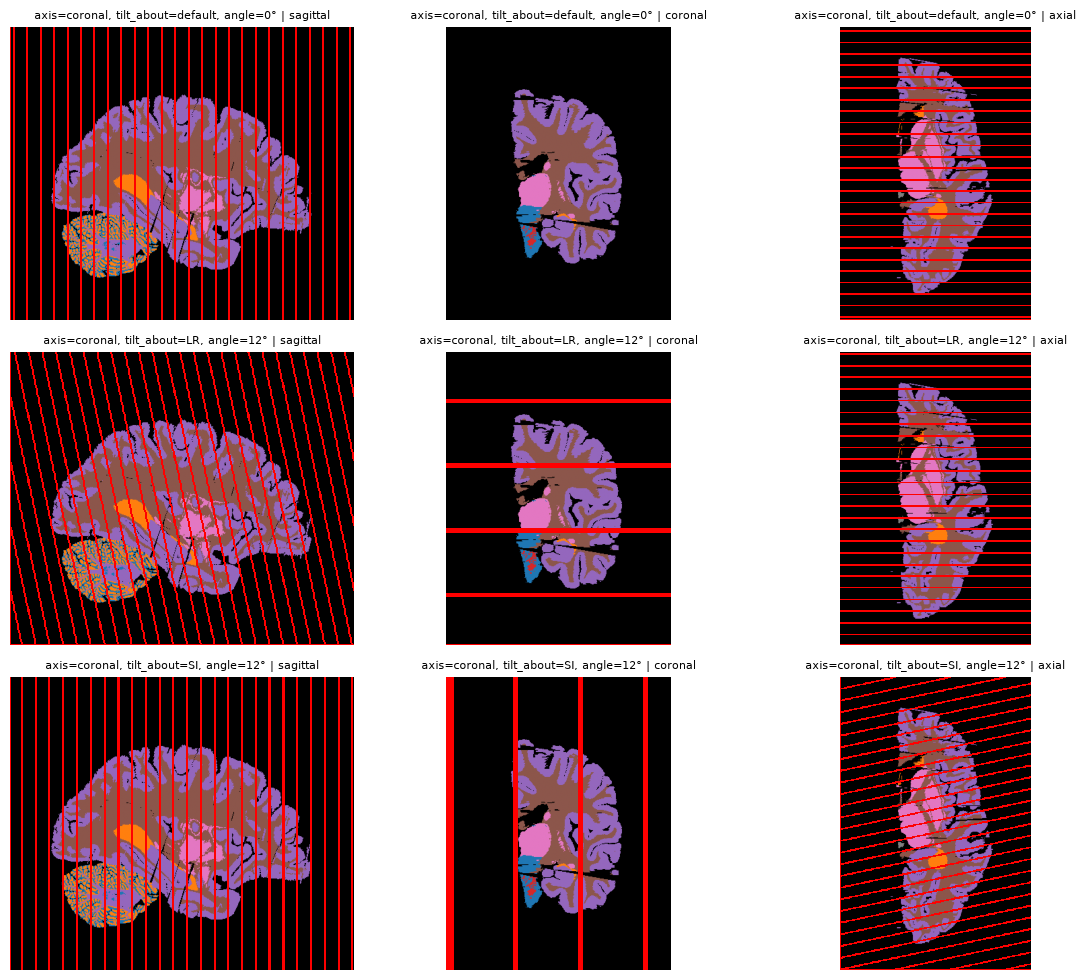

In [3]:
def show_boundaries(cases, thickness=8.0):
    fig, ax = plt.subplots(len(cases), 3, figsize=(12, 3.3 * len(cases)), squeeze=False)
    for r, (axis, tilt, angle) in enumerate(cases):
        b = np.asarray(boundaries_image(img, axis, tilt, angle, thickness).dataobj)
        for c, v in enumerate(VIEWS):
            ax[r, c].imshow(take(seg, v, CENTER[VIEWS[v]]), cmap=cmap, vmin=0, vmax=10, origin="lower")
            line = ndi.binary_dilation(take(b, v, CENTER[VIEWS[v]]) > 0, iterations=1)   # thicker for display
            ax[r, c].imshow(np.ma.masked_equal(line.astype(np.uint8), 0), cmap="autumn",
                            origin="lower", interpolation="nearest")
            ax[r, c].set_title(f"axis={axis}, tilt_about={tilt or 'default'}, angle={angle}° | {v}", fontsize=8)
            ax[r, c].axis("off")
    plt.tight_layout(); plt.show()

show_boundaries([
    ("coronal", None, 0),     # pure coronal sections
    ("coronal", "LR", 12),    # tilted around L-R  -> tilt visible in sagittal
    ("coronal", "SI", 12),    # tilted around S-I  -> tilt visible in axial
])

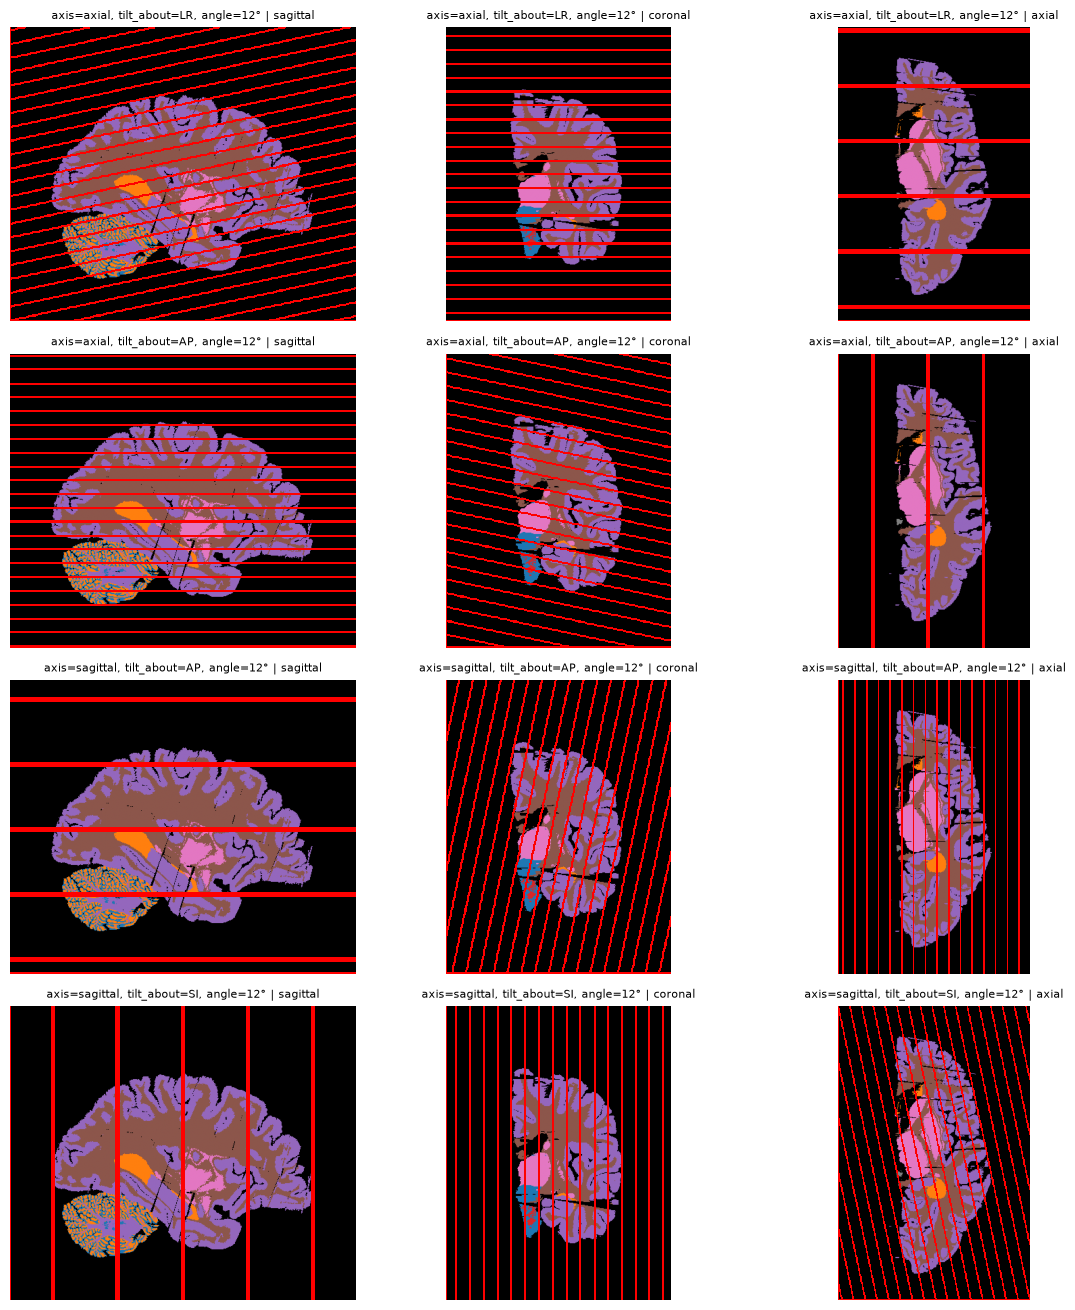

In [4]:
show_boundaries([
    ("axial", "LR", 12),      # axial planes, tilt visible in sagittal
    ("axial", "AP", 12),      # axial planes, tilt visible in coronal
    ("sagittal", "AP", 12),   # sagittal planes, tilt visible in coronal
    ("sagittal", "SI", 12),   # sagittal planes, tilt visible in axial
])

In [5]:
# tilting a plane around its own normal is rejected
try:
    run(axis="coronal", tilt_about="AP")
except ValueError as e:
    print("ValueError:", e)

ValueError: Cannot tilt a coronal plane around its own normal (AP).


### 2.2 `angle_range` and `random_sign`

For every sample, the angle is drawn uniformly from `angle_range`. With `random_sign=True` it is
negated with probability 0.5, i.e. the tilt can go in both directions. A fixed angle is obtained
with `angle_range=(a, a)`.

In [6]:
for kw in [dict(angle_range=(9, 14)),
           dict(angle_range=(9, 14), random_sign=True),
           dict(angle_range=(12, 12)),          # fixed angle
           dict(angle_range=(-5, 5))]:          # around the nominal plane
    angles = [run(seed=s, **OFF, **kw)[1]["angle_deg"] for s in range(8)]
    print(f"{str(kw):45s} -> " + "  ".join(f"{a:6.2f}" for a in angles))

{'angle_range': (9, 14)}                      ->  12.18   11.56   10.31    9.43   13.72   13.03   11.69   12.13
{'angle_range': (9, 14), 'random_sign': True} -> -12.18   11.56  -10.31   -9.43   13.72   13.03  -11.69   12.13
{'angle_range': (12, 12)}                     ->  12.00   12.00   12.00   12.00   12.00   12.00   12.00   12.00
{'angle_range': (-5, 5)}                      ->   1.37    0.12   -2.38   -4.14    4.43    3.05    0.38    1.25


### 2.3 `thickness`

* `thickness=None` (default) → the voxel size along the normal (0.2 mm at full resolution,
  0.4 mm in this demo). Each "section" is then one voxel thick.
* any value smaller than that is raised to it (`params["thickness_mm"]` reports the value used).
* thicker sections make **shifts and missing sections thicker**: a shifted section moves a slab
  of `thickness` mm, `slab_sections=(1, 3)` removes 1–3 × `thickness` mm, `block_sections`
  and `thin_sections` are also counted in sections.

Below: one missing-section event and a few section shifts for three thicknesses.

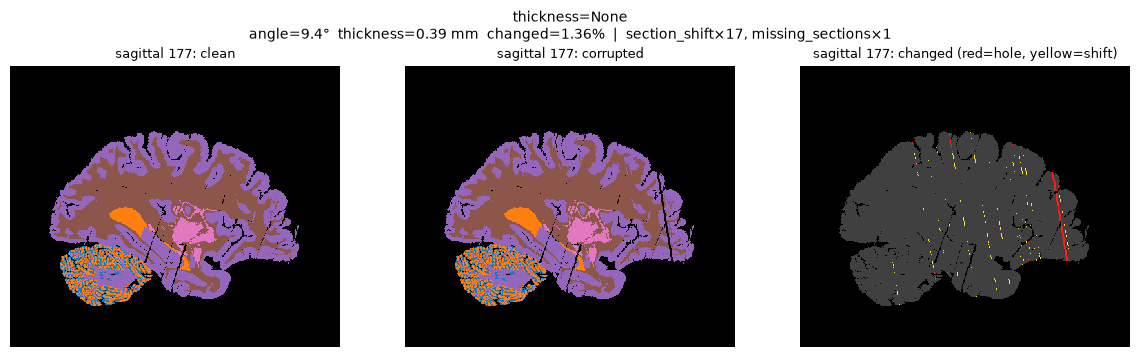

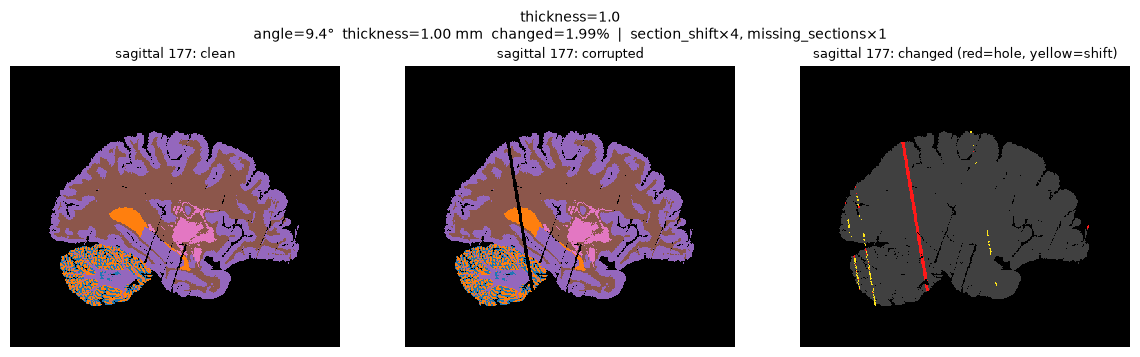

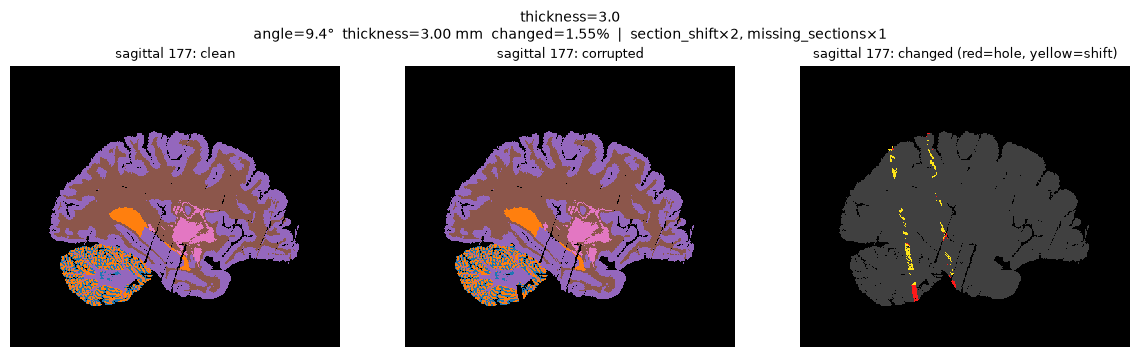

In [7]:
for t in [None, 1.0, 3.0]:
    x, p, _ = run(seed=3, **{**OFF, "p_slab": 1, "p_section": 0.05}, thickness=t)
    show(seg, x, p, views=("sagittal",), title=f"thickness={t}")

## 3. Each corruption alone

Each example starts from `OFF` (everything disabled) and enables a single corruption.

### 3.1 Section shifts — `p_section`, `shift_sd_mm`, `rot_sd_deg`

Every section that contains labels is shifted independently with probability `p_section`.
The motion is rigid **inside the section plane**: an in-plane translation with
N(0, `shift_sd_mm`) along each of the two in-plane axes and a rotation around the normal of
N(0, `rot_sd_deg`) degrees (about the centre of the volume).

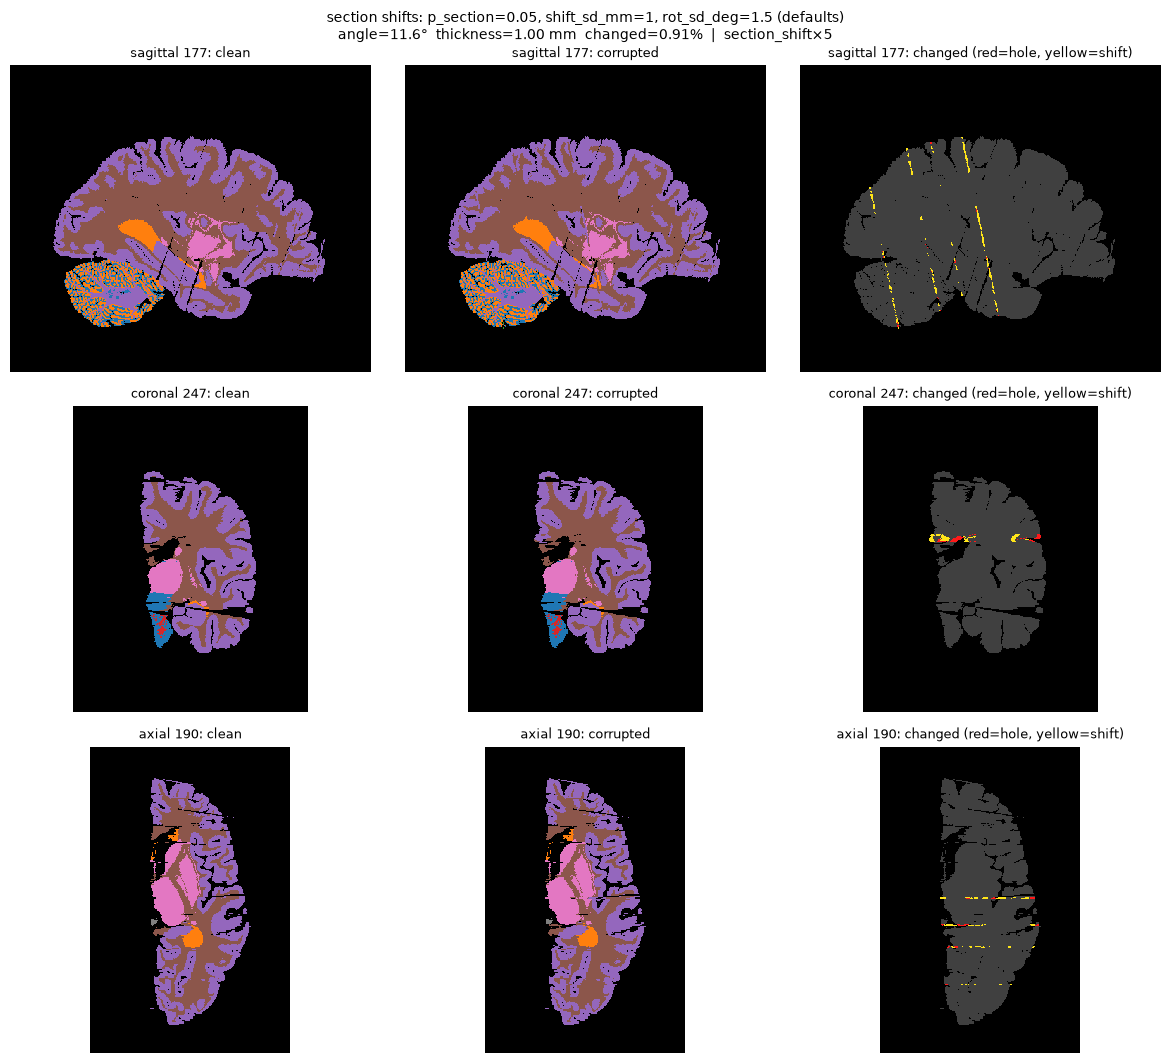

In [8]:
x, p, _ = run(seed=1, **{**OFF, "p_section": 0.05}, thickness=1.0)
show(seg, x, p, title="section shifts: p_section=0.05, shift_sd_mm=1, rot_sd_deg=1.5 (defaults)")

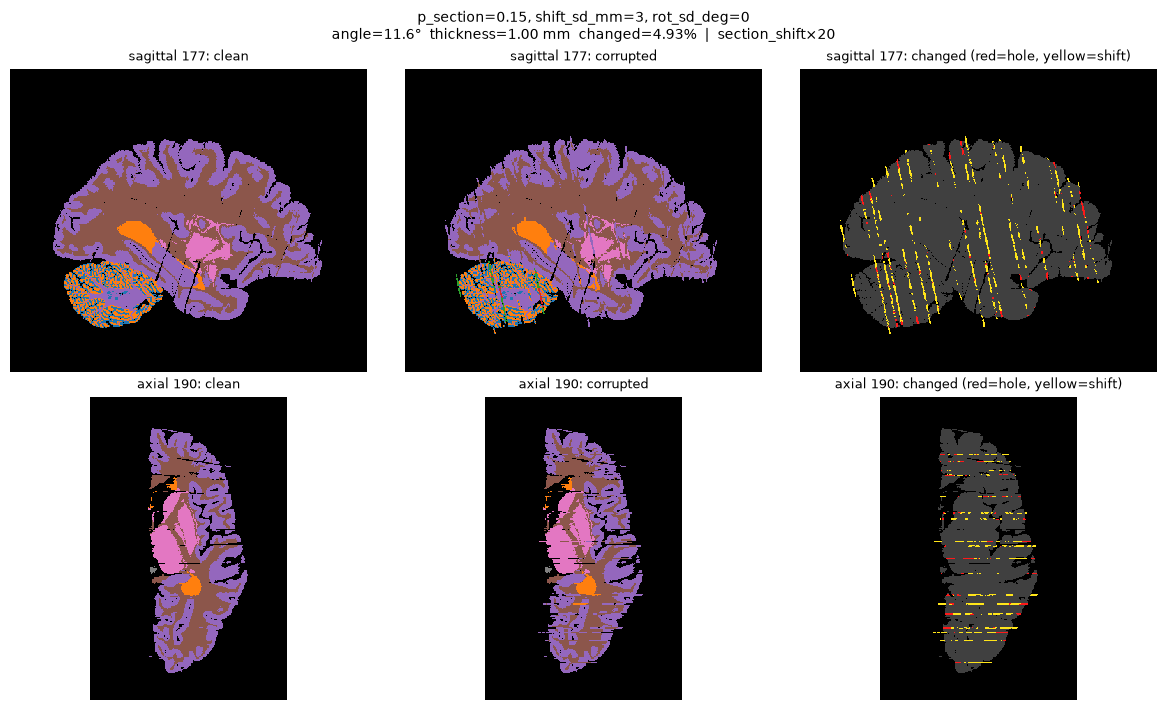

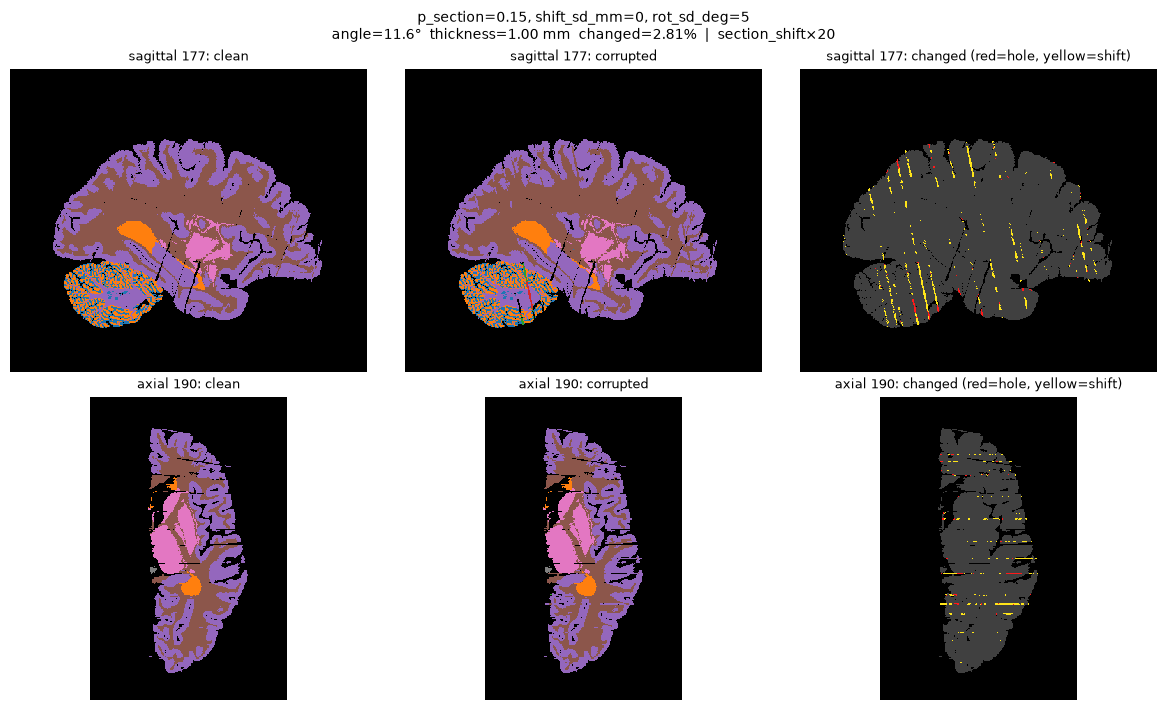

In [9]:
# larger and more frequent shifts, translation only (no rotation)
x, p, _ = run(seed=1, **{**OFF, "p_section": 0.15}, shift_sd_mm=3.0, rot_sd_deg=0, thickness=1.0)
show(seg, x, p, views=("sagittal", "axial"), title="p_section=0.15, shift_sd_mm=3, rot_sd_deg=0")

# rotation only (no translation)
x, p, _ = run(seed=1, **{**OFF, "p_section": 0.15}, shift_sd_mm=0, rot_sd_deg=5, thickness=1.0)
show(seg, x, p, views=("sagittal", "axial"), title="p_section=0.15, shift_sd_mm=0, rot_sd_deg=5")

### 3.2 Block shift — `p_block`, `block_sections`

With probability `p_block` (at most once per image) a block of `L` consecutive sections,
`L ∈ [block_sections[0], block_sections[1]]` (inclusive), starting at a random section, is moved with
one common in-plane motion (same `shift_sd_mm`, `rot_sd_deg`). The block size in mm is
`L × thickness`.

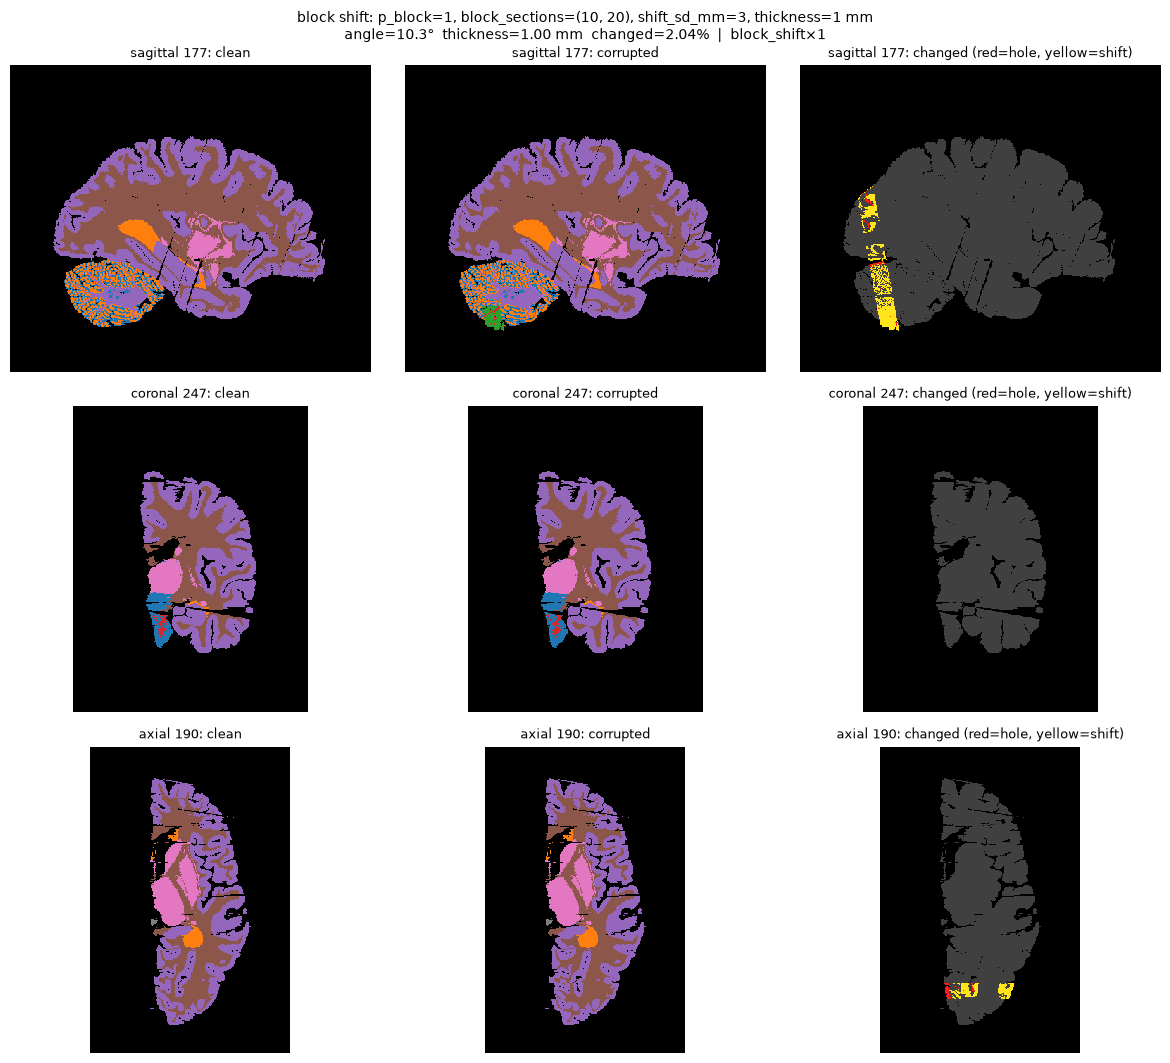

[{'type': 'block_shift', 'sections': [-76, -67], 'shift_mm': [2.654320001301734, 0.18583568204199918, -1.0217705677355988], 'rot_deg': 1.5649677677931326}]


In [10]:
x, p, _ = run(seed=2, **{**OFF, "p_block": 1}, block_sections=(10, 20), shift_sd_mm=3, thickness=1.0)
show(seg, x, p, title="block shift: p_block=1, block_sections=(10, 20), shift_sd_mm=3, thickness=1 mm")
print([e for e in p["events"] if e["type"] == "block_shift"])

### 3.3 Blob holes — `n_blobs`, `radius_mm`, `irregularity`

`n_blobs=(a, b)`: the number of holes is drawn uniformly in `[a, b]` (inclusive).
Each hole is an ellipsoid aligned with the section geometry (two in-plane radii + one radius
along the normal), each radius drawn from `radius_mm`, centred on a random brain voxel.
The surface is perturbed with smooth noise: `irregularity=0` gives clean ellipsoids, larger
values give more ragged shapes. Holes are set to label 0 and only inside the brain region
(section 5). `thin_prob=0` here so all holes are full 3D blobs.

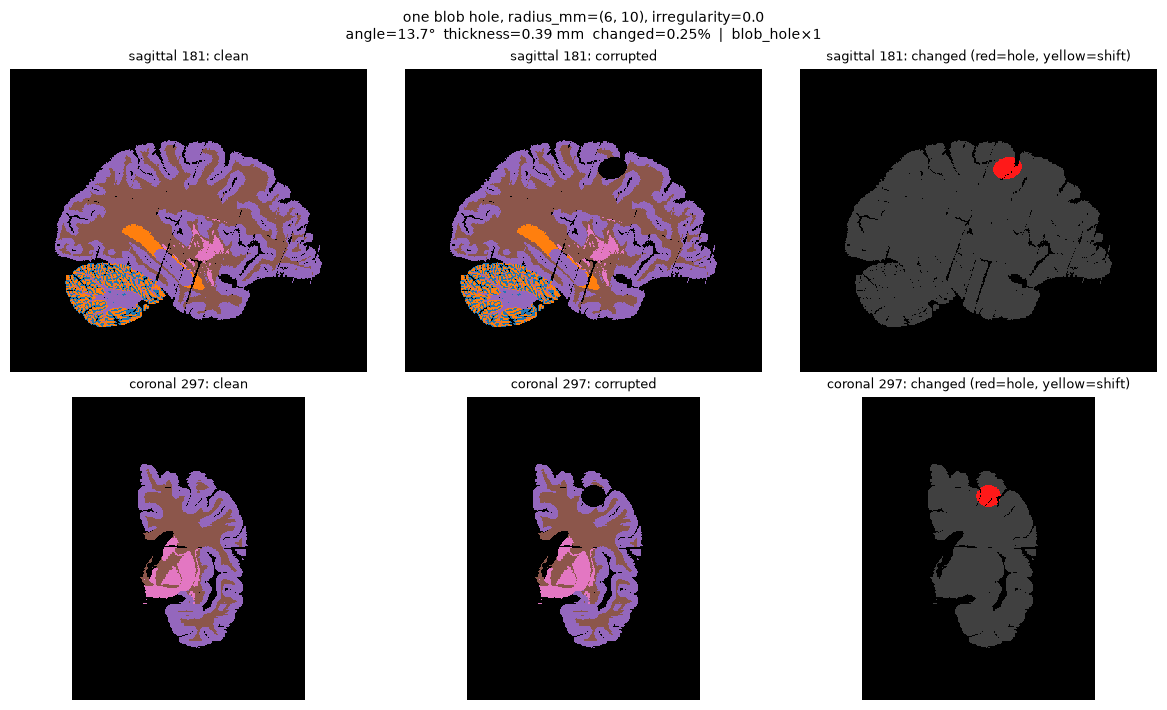

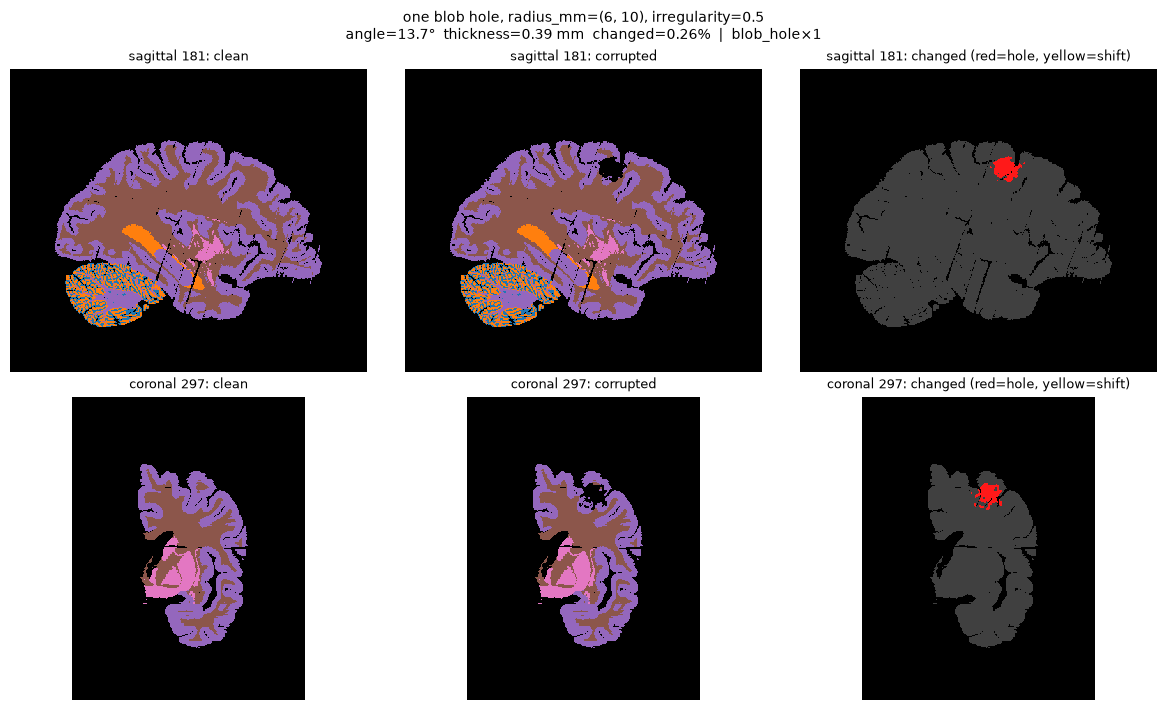

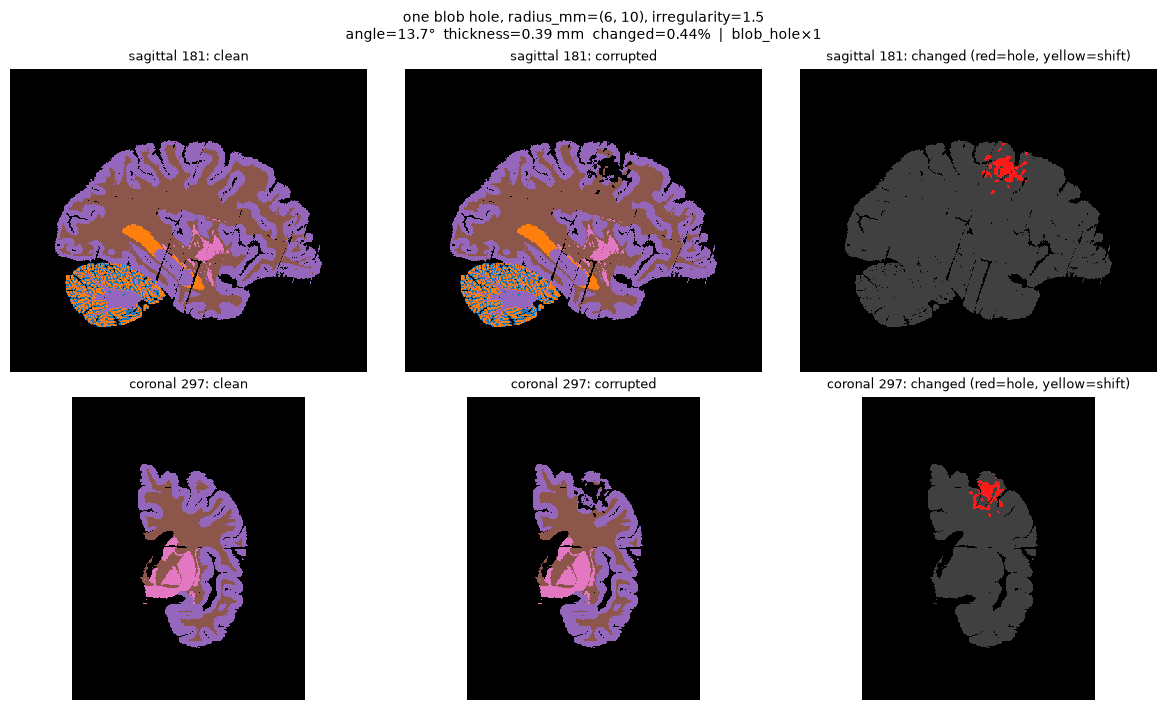

In [11]:
for irr in [0.0, 0.5, 1.5]:
    x, p, _ = run(seed=4, **{**OFF, "n_blobs": (1, 1)}, radius_mm=(6, 10), thin_prob=0, irregularity=irr)
    show(seg, x, p, views=("sagittal", "coronal"), title=f"one blob hole, radius_mm=(6, 10), irregularity={irr}")

15 holes, total voxels: 6868


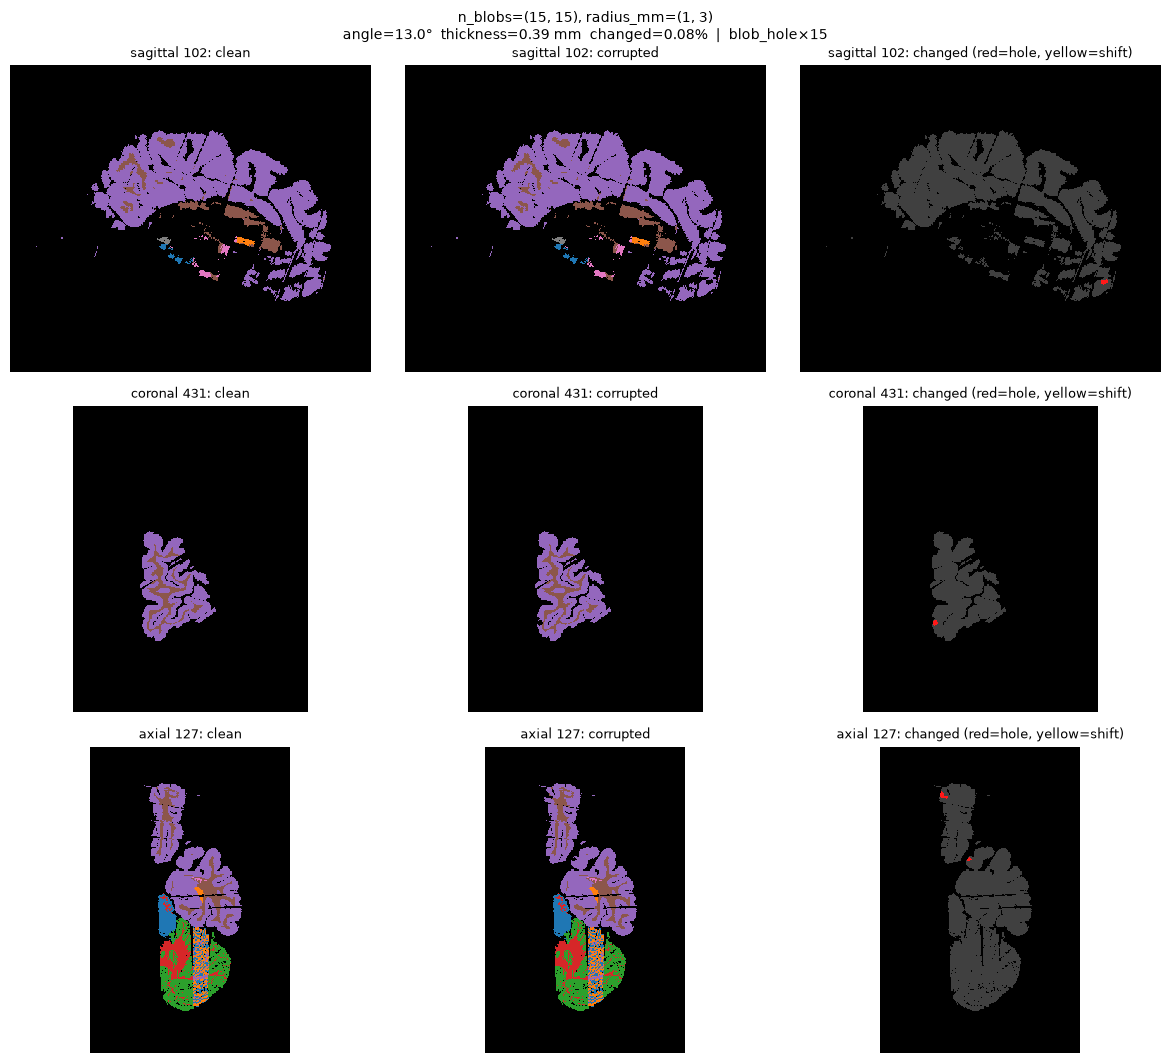

In [12]:
# many small holes
x, p, _ = run(seed=5, **{**OFF, "n_blobs": (15, 15)}, radius_mm=(1, 3), thin_prob=0)
print(sum(e["type"] == "blob_hole" for e in p["events"]), "holes, total voxels:",
      sum(e["voxels"] for e in p["events"]))
show(seg, x, p, title="n_blobs=(15, 15), radius_mm=(1, 3)")

### 3.4 Thin holes — `thin_prob`, `thin_sections`

Each hole becomes "thin" with probability `thin_prob`: it is cut to `k` consecutive sections,
`k ∈ [thin_sections[0], thin_sections[1]]`, starting at the section of its centre. This gives
flat holes lying exactly in the section planes (damage inside one or a few sections).
Their thickness is `k × thickness`.

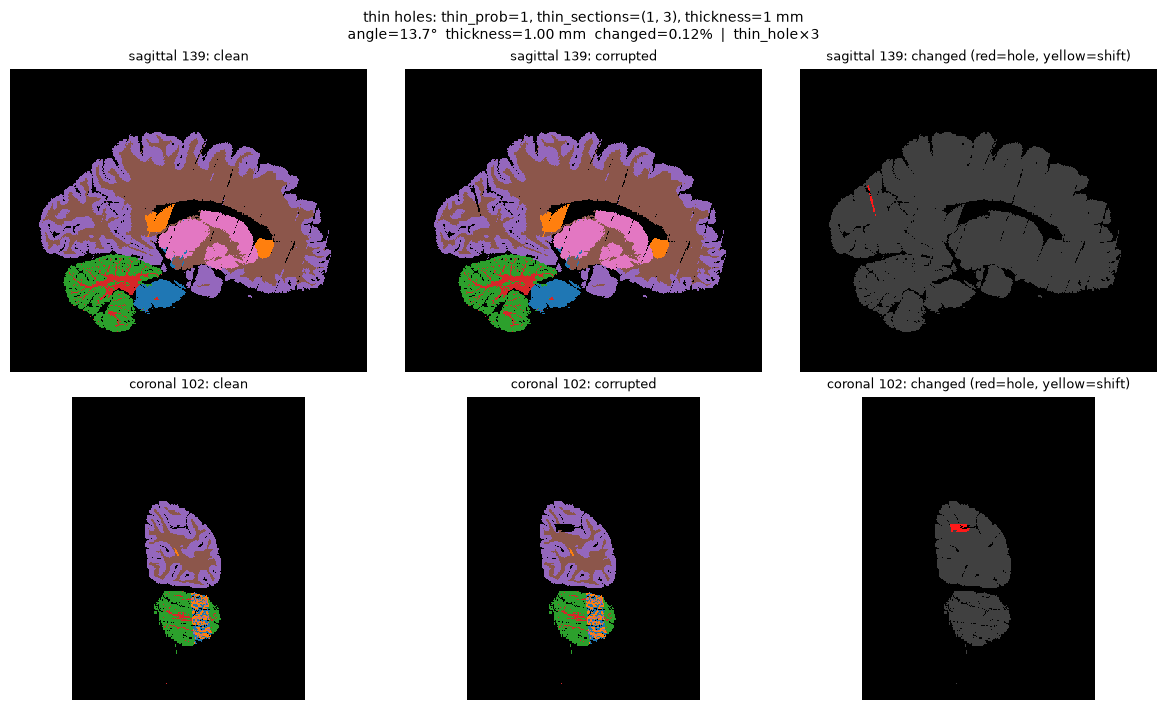

In [13]:
x, p, _ = run(seed=4, **{**OFF, "n_blobs": (3, 3)}, radius_mm=(5, 10), thin_prob=1,
              thin_sections=(1, 3), thickness=1.0)
show(seg, x, p, views=("sagittal", "coronal"),
     title="thin holes: thin_prob=1, thin_sections=(1, 3), thickness=1 mm")

### 3.5 Missing sections — `p_slab`, `slab_sections`

With probability `p_slab` (at most once per image), `k` consecutive whole sections
(`k ∈ [slab_sections[0], slab_sections[1]]`) are set to background inside the brain region.

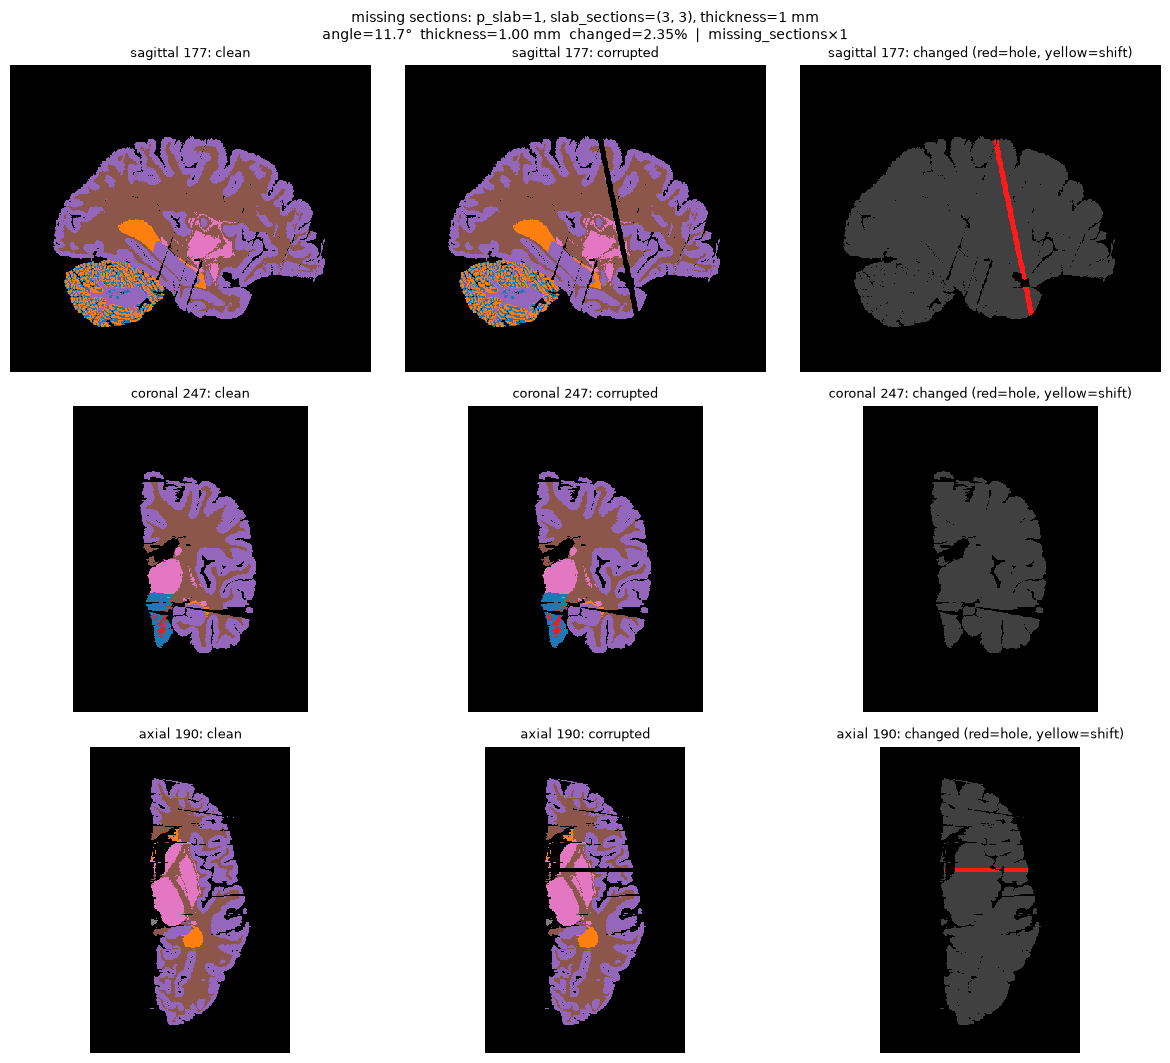

In [14]:
x, p, _ = run(seed=6, **{**OFF, "p_slab": 1}, slab_sections=(3, 3), thickness=1.0)
show(seg, x, p, title="missing sections: p_slab=1, slab_sections=(3, 3), thickness=1 mm")

## 4. Combining corruptions

All corruptions are applied in one call, in this order: section shifts → block shift →
blob/thin holes → missing sections. Holes are cut **after** the shifts, so they are never moved.

Some example presets (just dictionaries of keyword arguments):

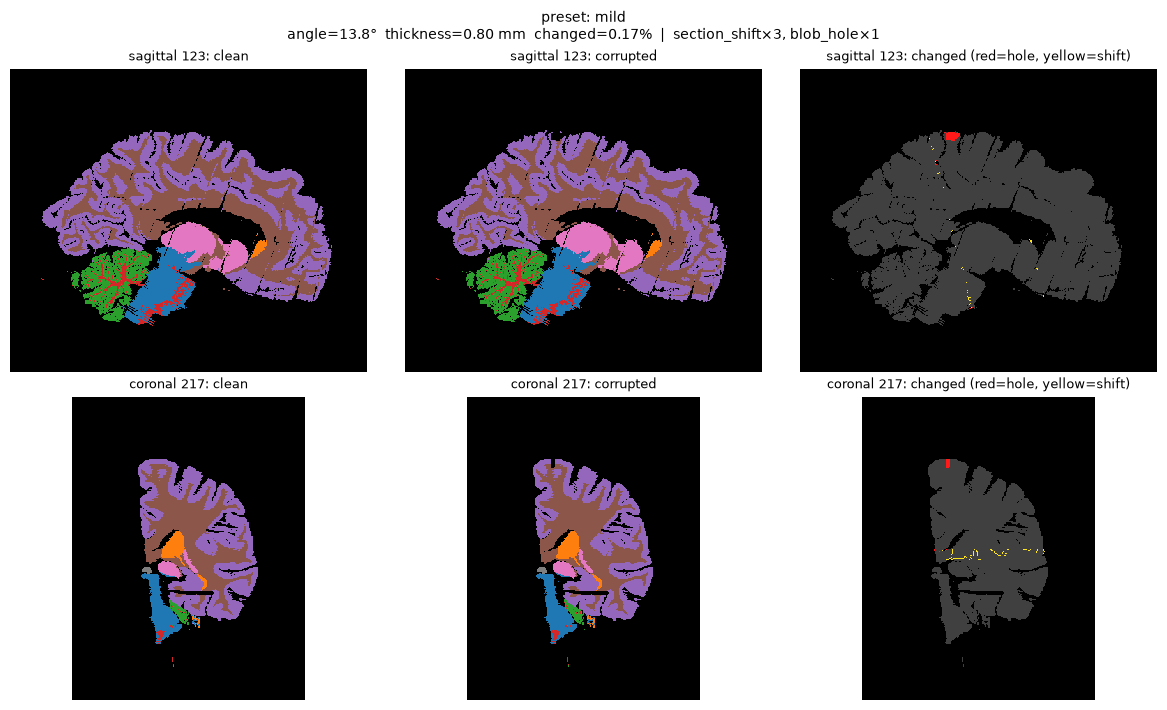

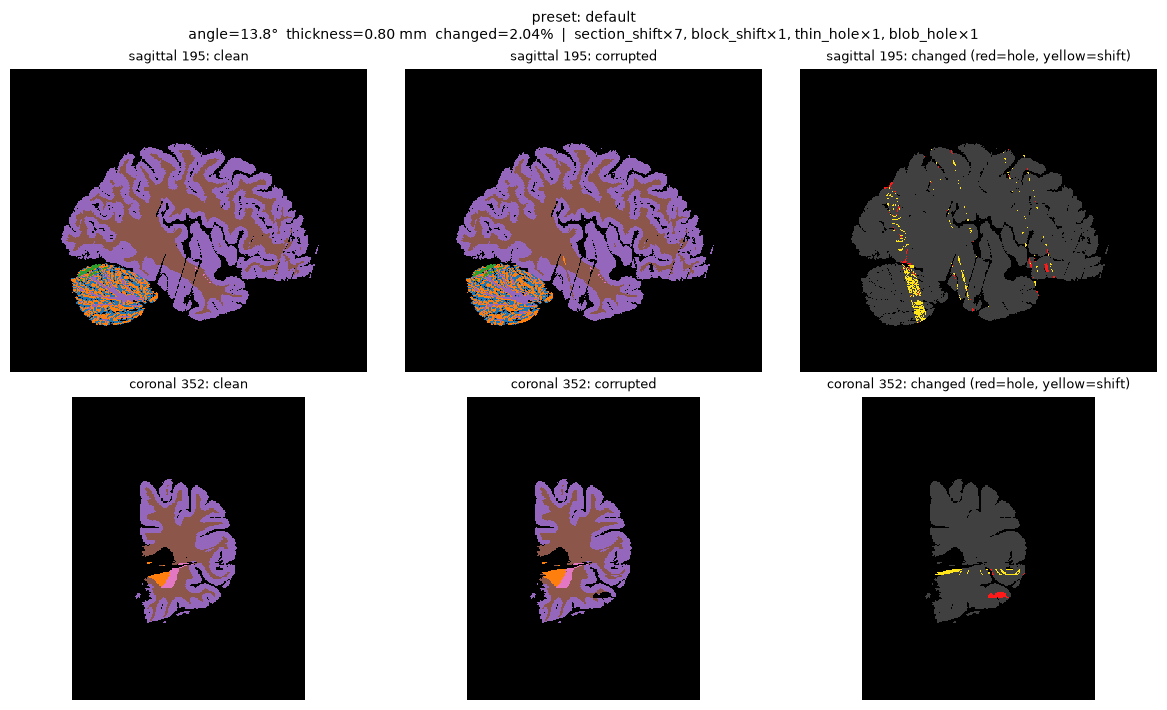

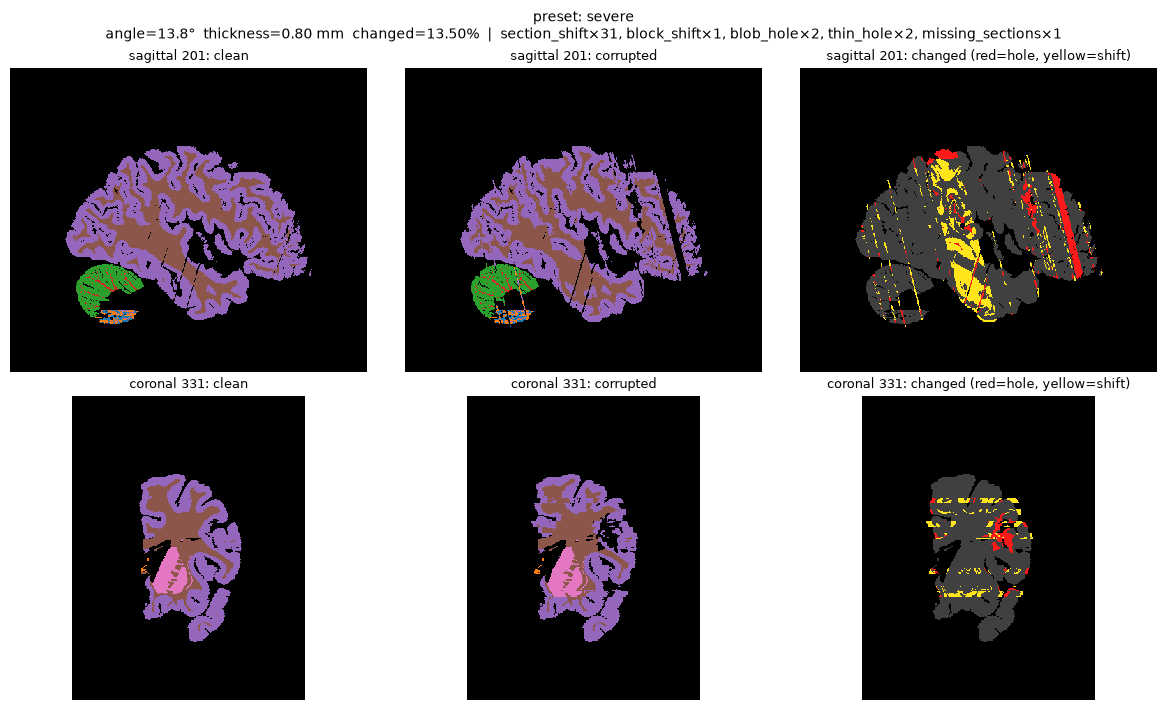

In [15]:
PRESETS = {
    "mild":    dict(p_section=0.02, p_block=0.1, shift_sd_mm=0.5, rot_sd_deg=0.5,
                    n_blobs=(0, 2), radius_mm=(1, 4), p_slab=0.05),
    "default": dict(),                                   # = DEFAULTS
    "severe":  dict(p_section=0.15, p_block=0.8, shift_sd_mm=2.0, rot_sd_deg=3.0, block_sections=(5, 25),
                    n_blobs=(4, 10), radius_mm=(2, 12), thin_prob=0.5, p_slab=0.7, slab_sections=(2, 5),
                    irregularity=0.8),
}
for name, kw in PRESETS.items():
    x, p, _ = run(seed=10, thickness=0.8, **kw)
    show(seg, x, p, views=("sagittal", "coronal"), title=f"preset: {name}")

## 5. Region where holes can be placed — `fill_brain_holes`

Holes and missing sections are only created inside the *brain mask*; `changed_fraction`
is also measured inside it.

* `fill_brain_holes=False` (default, for **clean** inputs): brain mask = `seg > 0`.
* `fill_brain_holes=True`: brain mask = binary closing (3 iterations) + hole filling of `seg > 0`.
  Useful if the input already has holes / unlabelled gaps inside the brain, so they are treated
  as brain. Slower (≈10 s extra at full resolution, computed once per input file).

Since holes only turn labels into 0, the corrupted image is affected only through *where* the
random hole centres / missing sections are drawn and through the denominator of
`changed_fraction`. Note that the closing also fills narrow sulci and gaps between structures,
so the mask is noticeably larger:

In [16]:
b0 = cn.brain_mask(seg, fill_holes=False)
b1 = cn.brain_mask(seg, fill_holes=True)
print(f"seg > 0 voxels:            {b0.sum():,}")
print(f"closing + fill holes:      {b1.sum():,}  (+{b1.sum() - b0.sum():,} voxels)")

seg > 0 voxels:            8,457,613
closing + fill holes:      9,025,931  (+568,318 voxels)


## 6. Reproducibility — `seed`, `n`

* `seed=None` → different results on every run; an integer → fully reproducible.
* `corrupt_nifti(..., n=N, seed=s)` creates **one** random generator and draws N different
  samples from it. The same `(seed, n)` always gives the same N samples.
* `corrupt_array` takes the generator itself (`rng`), so you control it.

In [17]:
a1, _, _ = run(seed=42)
a2, _, _ = run(seed=42)
a3, _, _ = run(seed=43)
print("same seed      -> identical:", np.array_equal(a1, a2))
print("different seed -> identical:", np.array_equal(a1, a3))

rng = np.random.default_rng(0)                     # one generator, several different samples
for i in range(3):
    _, p, _ = corrupt_array(seg, affine, (9, 14), "coronal", rng)
    print(f"sample {i}: angle={p['angle_deg']:.2f}  events={len(p['events'])}")

same seed      -> identical: True
different seed -> identical: False
sample 0: angle=12.18  events=21
sample 1: angle=10.42  events=29
sample 2: angle=9.96  events=26


## 7. The returned `params` dictionary

Every sample comes with a JSON-serialisable dictionary describing exactly what was done:

| key | meaning |
|---|---|
| `axis`, `tilt_about` | cutting plane and tilt axis used |
| `angle_deg` | sampled tilt (negative if `random_sign` flipped it) |
| `normal_ras` | unit normal of the section planes in world RAS coordinates |
| `thickness_mm`, `phase_mm` | section thickness actually used and boundary offset |
| `changed_fraction` | fraction of brain voxels whose label changed |
| `events` | list of corruptions applied (see below) |

Event types:

| `type` | fields |
|---|---|
| `section_shift` | `sections` [s], `shift_mm` (world vector), `rot_deg` |
| `block_shift` | `sections` [first, last], `shift_mm`, `rot_deg` |
| `blob_hole` / `thin_hole` | `center_vox` (i, j, k), `radii_mm` (u, v, normal), `voxels` removed |
| `missing_sections` | `sections` [first, last], `voxels` removed |

The third return value of `corrupt_array` is `sidx`, the section index of every voxel (useful e.g.
as an extra input channel or to find the voxels of a given section: `sidx == s`).

In [18]:
x, p, sidx = run(seed=10, thickness=0.8, **PRESETS["severe"])
print(json.dumps({k: v for k, v in p.items() if k != "events"}, indent=2))
for e in p["events"][:6]:
    print(e)
print("...", len(p["events"]), "events")
print("sidx:", sidx.shape, sidx.dtype, "range", sidx.min(), sidx.max())

{
  "axis": "coronal",
  "tilt_about": "LR",
  "angle_deg": 13.780008548144878,
  "normal_ras": [
    0.0,
    0.9712174490902594,
    0.23819459813902047
  ],
  "thickness_mm": 0.8,
  "phase_mm": 0.16614544806331752,
  "changed_fraction": 0.1349956542111823
}
{'type': 'section_shift', 'sections': [-126], 'shift_mm': [0.4754946851751976, 0.2531307215237131, -1.0321181738183327], 'rot_deg': -1.3246402003114772}
{'type': 'section_shift', 'sections': [-124], 'shift_mm': [1.6748968911153668, -0.21550494193203062, 0.8787023786635735], 'rot_deg': -0.9022889809891618}
{'type': 'section_shift', 'sections': [-113], 'shift_mm': [-0.6447943218535305, 0.11040159055548737, -0.4501527406269192], 'rot_deg': 2.869286009181687}
{'type': 'section_shift', 'sections': [-111], 'shift_mm': [1.2507792940505378, -0.03348299714109948, 0.1365239653852077], 'rot_deg': 2.1499095407474726}
{'type': 'section_shift', 'sections': [-94], 'shift_mm': [-1.7601141897482864, 0.11082727824241177, -0.45188844459600136], 'ro

## 8. Python APIs

| function | input | output | when to use |
|---|---|---|---|
| `corrupt_nifti(path, angle_range, axis="coronal", n=1, seed=None, **kw)` | NIfTI file path | generator of `(nib.Nifti1Image, params)` | files on disk; brain mask computed once for the N samples |
| `corrupt_array(seg, affine, angle_range, axis, rng, brain=None, fg_box=None, **kw)` | numpy label array + affine | `(array, params, sidx)` | data already in memory (e.g. inside a PyTorch `Dataset`) |
| `boundaries_image(img, axis, tilt_about, angle_deg, thickness, phase=0)` | nibabel image | NIfTI with section boundaries | QC in a viewer |
| `brain_mask(seg, fill_holes=False)` | label array | bool array | precompute once and pass as `brain=` to `corrupt_array` |

`**kw` is any key of `DEFAULTS`:

In [19]:
DEFAULTS

{'thickness': None,
 'tilt_about': None,
 'random_sign': False,
 'p_section': 0.05,
 'p_block': 0.3,
 'shift_sd_mm': 1.0,
 'rot_sd_deg': 1.5,
 'block_sections': (3, 15),
 'n_blobs': (0, 6),
 'radius_mm': (1.0, 8.0),
 'thin_prob': 0.5,
 'thin_sections': (1, 3),
 'p_slab': 0.2,
 'slab_sections': (1, 3),
 'irregularity': 0.5,
 'fill_brain_holes': False}

In [20]:
# corrupt_array inside a data loader: precompute what does not change per sample
brain = cn.brain_mask(seg)
fg_box = cn.bbox(seg > 0)
rng = np.random.default_rng(0)

t = time.time()
for _ in range(3):
    x, p, sidx = corrupt_array(seg, affine, (9, 14), "coronal", rng, brain=brain, fg_box=fg_box,
                               thickness=0.8, random_sign=True)
    # (input, target) pair for a restoration network: x -> seg
print(f"{(time.time() - t) / 3:.2f} s per sample (0.4 mm demo volume)")

0.93 s per sample (0.4 mm demo volume)


## 9. Generating a training dataset

Full-resolution files, several samples per file, image + params JSON (+ optional section
boundaries for QC). Here only 1 sample of one file is generated to keep the notebook short;
change `FILES` and `N_PER_FILE` for the real run.

In [21]:
import glob

FILES = sorted(glob.glob("data/test/changed_recon_holes_0.2mm_L1/case-*.nii.gz"))[:1]
OUT_DIR = "data/train/corrupted_images"
N_PER_FILE = 1
KW = dict(thickness=None, random_sign=False)        # any DEFAULTS key
SAVE_BOUNDARIES = False

os.makedirs(OUT_DIR, exist_ok=True)
for f_i, path in enumerate(FILES):
    base = os.path.basename(path).replace(".nii.gz", "")
    t = time.time()
    # seed per file -> reproducible and different for every file
    for i, (out_img, params) in enumerate(corrupt_nifti(path, (9, 14), "coronal",
                                                        n=N_PER_FILE, seed=1000 + f_i, **KW)):
        stem = f"{OUT_DIR}/{base}_corrupt_{i:03d}"
        nib.save(out_img, stem + ".nii.gz")
        with open(stem + ".json", "w") as fh:
            json.dump(params, fh, indent=2)
        if SAVE_BOUNDARIES:
            nib.save(boundaries_image(nib.load(path), params["axis"], params["tilt_about"],
                                      params["angle_deg"], params["thickness_mm"], params["phase_mm"]),
                     stem + "_boundaries.nii.gz")
        print(f"{stem}: angle={params['angle_deg']:.2f}°  changed={100 * params['changed_fraction']:.2f}%  "
              f"events={len(params['events'])}  ({time.time() - t:.1f} s)")
        t = time.time()

data/train/corrupted_images/case-1_corrupt_000: angle=11.61°  changed=1.33%  events=48  (15.7 s)


## 10. Command line usage

Same options as the Python API (`-` instead of `_`). Ranges take two values.
Output: `<out-dir>/<name>_corrupt_000.nii.gz` + `.json` (+ `_boundaries.nii.gz` with `--save-boundaries`).

```bash
# 20 samples, coronal planes tilted 9-14° (visible in sagittal), 1 mm sections, QC boundaries
python corrupt_nifti.py seg.nii.gz --out-dir corrupted --n 20 --seed 0 \
       --axis coronal --angle-range 9 14 --thickness 1.0 --save-boundaries

# tilt in both directions, tilted around S-I instead (visible in axial)
python corrupt_nifti.py seg.nii.gz --out-dir corrupted --n 20 \
       --axis coronal --tilt-about SI --angle-range 5 15 --random-sign

# only holes (no shifts), many thin holes and always a missing slab
python corrupt_nifti.py seg.nii.gz --out-dir corrupted --n 5 --angle-range 9 14 \
       --p-section 0 --p-block 0 --n-blobs 5 10 --thin-prob 1 --thin-sections 1 3 \
       --p-slab 1 --slab-sections 2 4

# only shifts, strong
python corrupt_nifti.py seg.nii.gz --out-dir corrupted --n 5 --angle-range 9 14 \
       --n-blobs 0 0 --p-slab 0 --p-section 0.1 --p-block 1 --block-sections 5 20 \
       --shift-sd-mm 2 --rot-sd-deg 3

# input that already has holes: treat unlabelled gaps inside the brain as brain
python corrupt_nifti.py seg.nii.gz --out-dir corrupted --angle-range 9 14 --fill-brain-holes
```

In [22]:
!python corrupt_nifti.py --help

usage: corrupt_nifti.py [-h] --out-dir OUT_DIR [--n N] --angle-range MIN MAX
                        [--axis {sagittal,coronal,axial}]
                        [--tilt-about {LR,AP,SI}] [--random-sign]
                        [--thickness THICKNESS] [--seed SEED]
                        [--p-section P_SECTION] [--p-block P_BLOCK]
                        [--shift-sd-mm SHIFT_SD_MM] [--rot-sd-deg ROT_SD_DEG]
                        [--block-sections BLOCK_SECTIONS BLOCK_SECTIONS]
                        [--n-blobs N_BLOBS N_BLOBS]
                        [--radius-mm RADIUS_MM RADIUS_MM]
                        [--thin-prob THIN_PROB]
                        [--thin-sections THIN_SECTIONS THIN_SECTIONS]
                        [--p-slab P_SLAB]
                        [--slab-sections SLAB_SECTIONS SLAB_SECTIONS]
                        [--irregularity IRREGULARITY] [--fill-brain-holes]
                        [--save-boundaries]
                        input

corrupt_nifti.py — Random Ne

## 11. Full parameter reference

| Python (`**kw`) | CLI | default | type | effect |
|---|---|---|---|---|
| `angle_range` | `--angle-range MIN MAX` | required | (float, float) | tilt in degrees, uniform per sample |
| `axis` | `--axis` | `coronal` | coronal / axial / sagittal | nominal cutting plane |
| `tilt_about` | `--tilt-about` | `None` → LR (coronal, axial), AP (sagittal) | LR / AP / SI | world axis of the tilt |
| `random_sign` | `--random-sign` | `False` | bool | negate the angle with p=0.5 |
| `thickness` | `--thickness` | `None` → voxel size along normal | float (mm) | section thickness (min = voxel size) |
| `p_section` | `--p-section` | 0.05 | prob. | probability each section is shifted |
| `p_block` | `--p-block` | 0.3 | prob. | probability of one block shift |
| `block_sections` | `--block-sections A B` | (3, 15) | ints, inclusive | sections in the block |
| `shift_sd_mm` | `--shift-sd-mm` | 1.0 | mm | SD of in-plane translation (each axis) |
| `rot_sd_deg` | `--rot-sd-deg` | 1.5 | degrees | SD of in-plane rotation |
| `n_blobs` | `--n-blobs A B` | (0, 6) | ints, inclusive | number of holes |
| `radius_mm` | `--radius-mm A B` | (1.0, 8.0) | mm | range of the 3 ellipsoid radii |
| `irregularity` | `--irregularity` | 0.5 | ≥ 0 | raggedness of hole borders (0 = ellipsoid) |
| `thin_prob` | `--thin-prob` | 0.5 | prob. | probability a hole is confined to few sections |
| `thin_sections` | `--thin-sections A B` | (1, 3) | ints, inclusive | sections spanned by a thin hole |
| `p_slab` | `--p-slab` | 0.2 | prob. | probability of one missing-sections event |
| `slab_sections` | `--slab-sections A B` | (1, 3) | ints, inclusive | number of missing sections |
| `fill_brain_holes` | `--fill-brain-holes` | `False` | bool | brain mask = closing + fill holes (instead of `seg > 0`) |
| `seed` | `--seed` | `None` | int | random seed |
| `n` | `--n` | 1 (Python) / 10 (CLI) | int | samples per input file |
| – | `--out-dir` | required | path | output folder (CLI) |
| – | `--save-boundaries` | off | flag | also save section boundaries (CLI) |

**Tips**
* To disable a corruption: `p_section=0`, `p_block=0`, `n_blobs=(0, 0)`, `p_slab=0`.
* To force it: probability `1`, or a fixed count like `n_blobs=(3, 3)`.
* Section-counted parameters (`block_sections`, `thin_sections`, `slab_sections`) scale with `thickness`.
* `changed_fraction` is a quick severity measure to filter or balance the generated dataset.